## Generate cell population data for figure 3 for all six conditions

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from pathlib import Path
import datetime
import pickle
sys.path.insert(0, "./cellular_cycle")
sys.path.insert(0, "./figures")

from cell_cycle_death_model import model
from pysb.simulator import BngSimulator
from pysb.simulator import ScipyOdeSimulator
from model_fxns import *
from Cell_Population_Simulation import Cell_Population_Simulation
from SMs_G1s_IMTs_extraction import SMs_G1s_IMTs_extraction

In [2]:
# Directory containing cell fate data
DATADIR = Path('../data/Exp_Intermitotic_Times/')

# Where to save large simulation output files
SAVE_DIR = Path(Path.home(),'ECM_mod_output')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

OVERWRITE = False # Overwrite existing simulation files

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

In [3]:
# import pysb sampled parameters
sampled_parameter_names = np.loadtxt(os.getcwd() + '/model_data/sampled_parameter_names.txt', dtype=str)

In [4]:
# Importing the parameters:
new_param = pd.read_csv(os.getcwd()+ '/test_treatments/parameters.csv')
for key in new_param.keys():
    try:
        if model.parameters[key].value != new_param[key][0]:
            model.parameters[key].value = new_param[key]
    except:
        print(key)
model.parameters['omega'].value = 200

Stress
b
Hippo_tot
Yap_tot
AKT_tot
ERK_tot
FAK_tot
skp2_tot
p21_tot
cdh1_tot
CycD_tot
K_1E2F
V_1E2F
k_cd4
k_myc1
k_CE
d_CE
K_i13
K_i14
V_sac
V_da
V_sec
V_de
V_sf
V_fs
V_dfa
v_scdh1a
v_2fak
v_s2p21
K_AFAK
K_dfa
K_fs
K_cf
K_cac
K_cec
K_da
K_de
K_sp21
k_dcdh1a
K_p21fak.1
k_CDF
K_DF
K_dcescp2


In [5]:
# Setting initial concentrations '/../model_data/initial_concentrations.csv'
initial_concentrations = pd.read_csv(os.getcwd() + '/model_data/initial_concentrations.csv')
for key in initial_concentrations.keys():
    try:
        model.parameters[key].value = initial_concentrations[key][0] / model.parameters['omega'].value
    except:
        print(key)

BAXm_0
BCL2_0


In [6]:
# Import ECM_conditions.csv
ECM_conditions = pd.read_csv(os.getcwd() + '/model_data/ECM_conditions_2.csv')
ECM_conditions


,condition,stiffness,drug,species,value
0,55 kPa DMSO,55 kPa,DMSO,AKT,1.0
1,55 kPa DMSO,55 kPa,DMSO,ERK,1.0
2,55 kPa DMSO,55 kPa,DMSO,FAK,1.0
3,4 kPa DMSO,4 kPa,DMSO,AKT,1.0
4,4 kPa DMSO,4 kPa,DMSO,ERK,1.0
5,4 kPa DMSO,4 kPa,DMSO,FAK,0.6
6,0.6 kPa DMSO,0.6 kPa,DMSO,AKT,0.6
7,0.6 kPa DMSO,0.6 kPa,DMSO,ERK,1.0
8,0.6 kPa DMSO,0.6 kPa,DMSO,FAK,0.4
9,55 kPa erlotinib,55 kPa,erlotinib,AKT,0.6


ld: warning: duplicate -rpath '/Users/darren/miniforge3/envs/ecm_model/lib' ignored


<Axes: xlabel='Time (h)', ylabel='Concentration'>

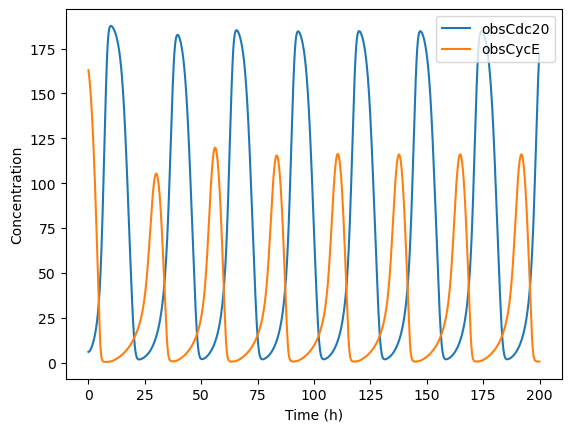

In [7]:
condition = "55 kPa erlotinib"

t = np.linspace(0, 20000, 200001)

model.parameters['AKT'].value = 0.6
model.parameters['ERK'].value = 0.2
model.parameters['FAK'].value = 1
# t = np.linspace(0, 50000, 500001)
sim_ode = ScipyOdeSimulator(model, t, verbose=False).run(); #deterministic simulation

observables=['obsCdc20', 'obsCycE']
plotObs(model=sim_ode.all, obs=observables, times=t, tpos=range(0,2000), legend=True)


<Axes: xlabel='Time (h)', ylabel='Concentration'>

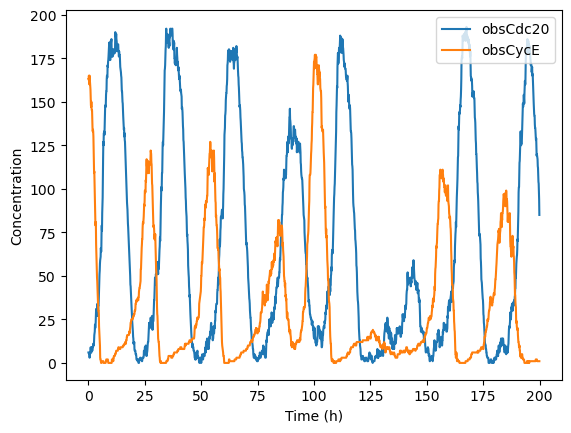

In [8]:
sim_stoch = BngSimulator(model, tspan=t, verbose=False)
sim_stoch_res = sim_stoch.run(method='ssa', verbose=False)
observables=['obsCdc20', 'obsCycE']
plotObs(model=sim_stoch_res.all, obs=observables, times=t, tpos=range(0,2000), legend=True)


### Run example simulation
Use low stiffness and DMSO treatment as condition. Must use more cells to get decent output.

In [9]:
start_time = datetime.datetime.now()

init = 10
run_time = 120
observed_cells_time = 120

In [10]:
# Run the model
# Simulate Check_Model_Consistency
# (variable_range, check, tmp_score) = Check_Model_Consistency(model, thr=0.26, return_plot=True)

(check, population_df, cells, cell_count) = Cell_Population_Simulation(init, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, thr=[0.26, 0.14], return_plot=False, bypass=True)
current_time = datetime.datetime.now()
print(f'elapsed time is {(current_time-start_time)/60} minutes')

55 kPa erlotinib
BAXm_0
BCL2_0
elapsed time is 0:00:01.851041 minutes


In [11]:
cell_count

array([[  0.        ,  14.        ],
       [  0.40133779,  15.        ],
       [  6.72240803,  16.        ],
       [  7.02341137,  17.        ],
       [  8.82943144,  18.        ],
       [ 10.93645485,  19.        ],
       [ 13.5451505 ,  20.        ],
       [ 14.14715719,  21.        ],
       [ 16.4548495 ,  22.        ],
       [ 16.75585284,  23.        ],
       [ 17.05685619,  24.        ],
       [ 17.55852843,  25.        ],
       [ 18.16053512,  26.        ],
       [ 18.46153846,  27.        ],
       [ 20.86956522,  28.        ],
       [ 21.37123746,  29.        ],
       [ 26.78929766,  30.        ],
       [ 29.69899666,  31.        ],
       [ 30.        ,  31.        ],
       [ 30.40133779,  31.        ],
       [ 32.7090301 ,  32.        ],
       [ 32.80936455,  33.        ],
       [ 35.11705686,  34.        ],
       [ 36.72240803,  34.        ],
       [ 37.02341137,  34.        ],
       [ 37.42474916,  36.        ],
       [ 38.82943144,  36.        ],
 

In [12]:
import fracprolif as fp

In [13]:
population_history = population_df
parameters_sim = {}

In [14]:
population_df

,Old ID,New ID,Lineage,Event,Start Time,Birth Time,End Time,Starting Cell,Lifetime
0,0,0,Initial cell,Mitosis,0.000000,Initial cell,13.545151,True,13.545151
1,0,214,0,Mitosis,13.545151,13.545151,39.632107,False,26.086957
2,0,215,214,Mitosis,39.632107,39.632107,60.000000,False,20.367893
3,0,216,215,Mitosis,60.000000,60.0,89.598662,False,29.598662
4,0,217,216,Apoptosis,89.598662,89.598662,114.180602,False,24.581940
...,...,...,...,...,...,...,...,...,...
413,209,209,388,End of experiment,116.863821,116.863821,120.069360,False,3.205539
414,210,210,401,End of experiment,107.658863,107.658863,120.090377,False,12.431514
415,211,211,411,End of experiment,117.577374,117.577374,120.066557,False,2.489183
416,212,212,196,End of experiment,113.076923,113.076923,120.085799,False,7.008876


In [15]:
def calc_rates(population_df):
    population_history = population_df
    parameters_sim = {}
    if len(population_history) > 0:
        number_of_deaths = len(population_history) - (population_history['Event']=='Apoptosis').value_counts()[0]
        cell_time_total = sum(population_history['Lifetime'])
        parameters_sim['a'] = number_of_deaths/cell_time_total
    else:
        parameters_sim['a'] = np.nan

    population_df = population_history[population_history['Starting Cell'] == False]
    mitotic_lifespans = population_df['Lifetime'][population_df['Event'] == 'Mitosis']
    censored_lifespans = population_df['Lifetime'][population_df['Event'] == 'End of experiment']

    if len(mitotic_lifespans) > 2:
        m = fp.mle(mitotic_lifespans, censored_lifespans)
        parameters_sim['mu'] = m['x'][0]
        parameters_sim['sigma'] = m['x'][1]
        parameters_sim['lambda'] = m['x'][2]
        parameters_sim.update(fp.q_rates(m))
    else:
        parameters_sim['d'] = np.nan
        parameters_sim['q'] = np.nan
        parameters_sim['mu'] = np.nan
        parameters_sim['sigma'] = np.nan
        parameters_sim['lambda'] = np.nan
        
    return parameters_sim, number_of_deaths, len(mitotic_lifespans)

In [16]:
parameters_sim

{}

In [17]:
def plot_cell_count(cell_count, run_time, title="Unknown condition"):
    t_sim = np.arange(0, run_time, 1 / 3)
    cell_count_t = np.zeros(len(t_sim))
    time_tmp_m = 0
    for time_tmp_p, cell_count_time_tmp in cell_count:
        cell_count_t[(time_tmp_m <= t_sim) & (t_sim < time_tmp_p)] = cell_count_time_tmp
        time_tmp_m = time_tmp_p
    pop_dubs = np.log2(cell_count_t / cell_count_t[0])
    fig, ax = plt.subplots()
    ax.scatter(t_sim, pop_dubs, color="black", s=1)
    ax.set_xlabel('Time (h)')
    ax.set_ylabel('Population doublings')
    ax.set_ylim(0,5)
    plt.text(0,4.5,title)
    plt.show()

    return fig, ax

In [18]:
def make_fig(cell_count, run_time, title="Unknown condition"):
    fig, ax = plt.subplots()
    
    ax.set_xlabel('Time (h)')
    ax.set_ylabel('Population doublings')
    ax.set_ylim(0,5)
    plt.text(0,4.5,title)
    
    return fig, ax

In [19]:
def add_plot(cell_count, run_time, fig, ax, title="Unknown condition", color="black"):
    t_sim = np.arange(0, run_time, 1 / 3)
    cell_count_t = np.zeros(len(t_sim))
    time_tmp_m = 0
    for time_tmp_p, cell_count_time_tmp in cell_count:
        cell_count_t[(time_tmp_m <= t_sim) & (t_sim < time_tmp_p)] = cell_count_time_tmp
        time_tmp_m = time_tmp_p
    pop_dubs = np.log2(cell_count_t / cell_count_t[0])
    ax.plot(t_sim, pop_dubs, color=color, lw=0.5, alpha=0.8)

    return

### New plotting function
Use seaborn and pandas. Should also save output files as csv (or parquet or feather) to maximize cross compatibility. Simple save procedure once data are in pandas DataFrame.  

In [20]:
def make_cellcount_df(cell_count_dat):
    dtp = pd.DataFrame(cell_count_dat)
    dtp.columns = ['Time (h)','Cell count','condition']
    dtp['Population doublings'] = pd.Series([dtp['Cell count'][dtp['condition']==cond] for cond in dtp['condition'].unique()])

def plot_popgrowth(cell_count_df):
    sns.scatterplot(data=cell_count_df, x='Time (h)', y='Population doublings', hue='condition')

In [21]:
# cells['molecules'][3]

In [22]:
model.parameters['CycDi_0'].value

0.0

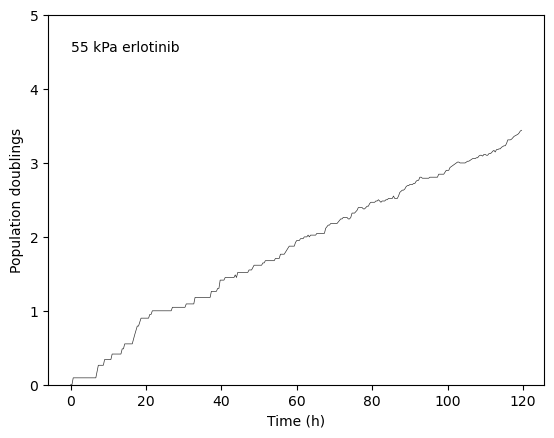

In [23]:
fig, ax = make_fig(cell_count, run_time, title=condition)
add_plot(cell_count, run_time, fig, ax, title=condition)

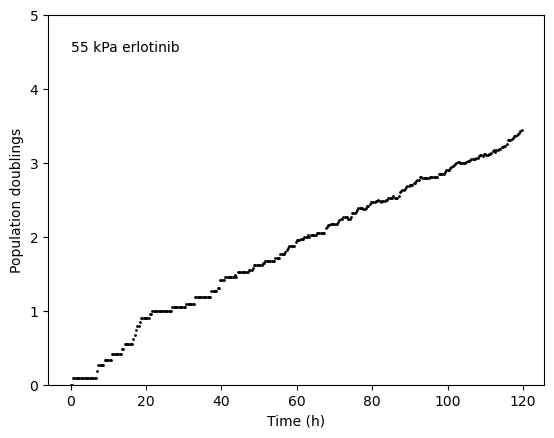

(<Figure size 640x480 with 1 Axes>,
 <Axes: xlabel='Time (h)', ylabel='Population doublings'>)

In [24]:
plot_cell_count(cell_count, run_time, title=condition)

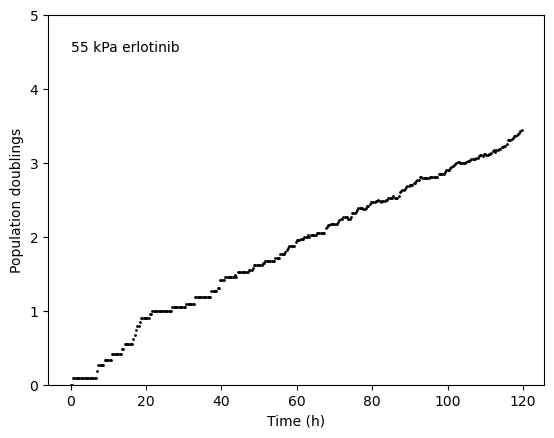

(<Figure size 640x480 with 1 Axes>,
 <Axes: xlabel='Time (h)', ylabel='Population doublings'>)

In [25]:
plot_cell_count(cell_count, run_time, title=condition)

In [26]:
from call_cell_events import call_events #
from retrieve_cellState_dw_2 import retrieve_cellState #

(0.0, 125.0)

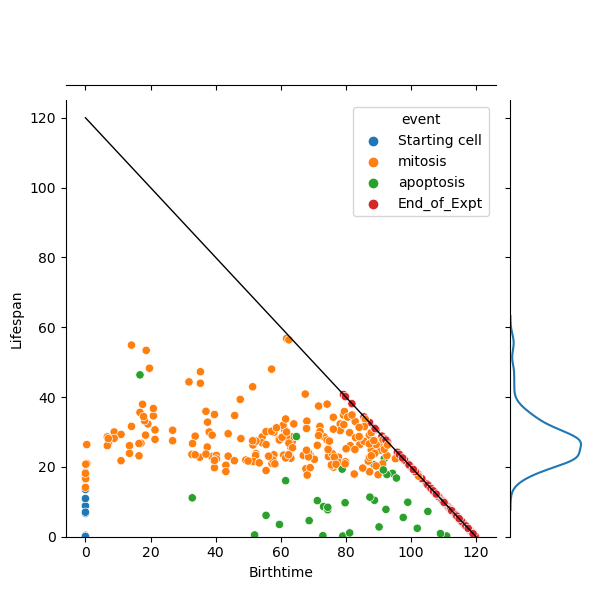

In [27]:
IMT_eoe_counts, all_prot = retrieve_cellState(run_time, cells, return_all_prot=True)
all_events_simulated = call_events(run_time, IMT_eoe_counts) #Gives all events (apoptosis, mitosis, quiescence) and when they happen

#plot the results
grid = sns.JointGrid(x='Birthtime', y='Lifespan', data=all_events_simulated) #x axis = birthtime of a cell, y = endtime of this cell
g = grid.plot_joint(sns.scatterplot, hue='event', data=all_events_simulated) 
g.ax_joint.plot([run_time, 0], [0, run_time], 'b-', linewidth = 1, color='black') #Recorded events behind this line
sns.kdeplot(all_events_simulated.loc[all_events_simulated['event']=='mitosis', 'Lifespan'].to_list(), 
            ax=g.ax_marg_y, vertical=True, legend=False, bw=0.3) #output distribution of intermitotic times
plt.ylim(0, 125)

In [28]:
all_prot

,Starting cell,End of experiment,Apoptosis,index,relative time,experiment time,Skp2,p21,p21p,cdh1act,...,BH3,BH3BCL2,BAXm,BCL2,CycDi,CycEi,CycAi,CycBi,E2Fi,Cdc20i
0,1.0,0.0,0.0,0.0,0.000000,0.000000,13.0,0.0,0.0,25.0,...,0.0,7.0,0.0,149.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.0,0.0,0.0,0.0,0.100334,0.100334,13.0,0.0,0.0,24.0,...,0.0,7.0,0.0,147.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.0,0.0,0.0,0.0,0.200669,0.200669,13.0,0.0,0.0,24.0,...,0.0,9.0,0.0,144.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.0,0.0,0.0,0.0,0.301003,0.301003,14.0,0.0,0.0,23.0,...,0.0,11.0,0.0,143.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.0,0.0,0.0,0.0,0.401338,0.401338,14.0,0.0,0.0,15.0,...,0.0,12.0,0.0,140.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
80298,0.0,1.0,0.0,420.0,0.318819,119.405906,25.0,10.0,1.0,4.0,...,1.0,114.0,0.0,37.0,0.0,0.0,0.0,0.0,0.0,0.0
80299,0.0,1.0,0.0,420.0,0.425092,119.512179,25.0,10.0,1.0,1.0,...,2.0,113.0,1.0,39.0,0.0,0.0,0.0,0.0,0.0,0.0
80300,0.0,1.0,0.0,420.0,0.531365,119.618452,24.0,8.0,0.0,8.0,...,1.0,114.0,0.0,36.0,0.0,0.0,0.0,0.0,0.0,0.0
80301,0.0,1.0,0.0,420.0,0.637638,119.724725,24.0,8.0,0.0,3.0,...,0.0,114.0,0.0,36.0,0.0,0.0,0.0,0.0,0.0,0.0


In [29]:
all_prot['BCL2'][0]

149.0

In [30]:
death_mod={'BAX_0': 186 ,'BAXmBCL2_0': 13, 'BH3_0': 0, 'BH3BCL2_0': 7, 'BAXm_0': 0, 'BCL2_0': 149}

In [31]:
def calc_death(cells, all_events_simulated):
    EXPT_TIME = 120
    total_time = 0
    for n in range(len(cells['time'])):
        if cells['time'][n][-1] > EXPT_TIME:
            total_time = total_time + (EXPT_TIME - cells['time'][n][0])
        else:
            total_time = total_time + (cells['time'][n][-1] - cells['time'][n][0])
    try:
        num_deaths = len(all_events_simulated[all_events_simulated['event']=='apoptosis'])
    except:
        num_deaths = 0
    a_rate = num_deaths/total_time
    
    return [a_rate, num_deaths, total_time]

In [32]:
test = calc_death(cells, all_events_simulated)
test

[0.004130113553305364, 34, 8232.219177797066]

In [33]:
test = calc_death(cells, all_events_simulated)
test

[0.004130113553305364, 34, 8232.219177797066]

In [34]:
len(all_events_simulated[all_events_simulated['event']=='apoptosis'])

34

(0.0, 125.0)

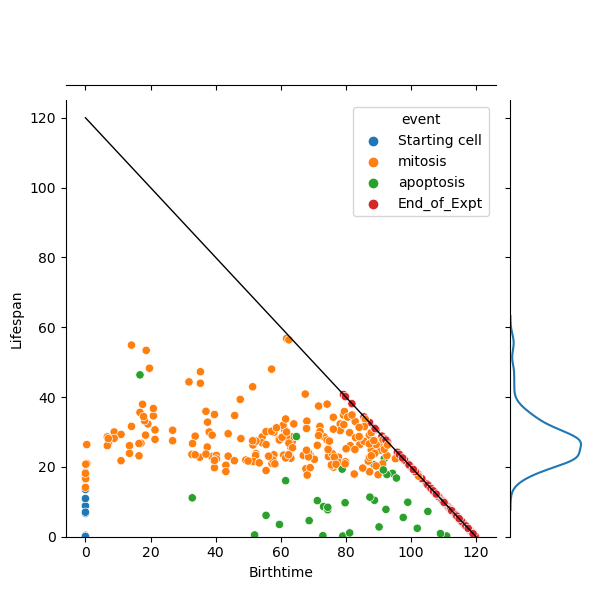

In [35]:
IMT_eoe_counts, all_prot = retrieve_cellState(run_time, cells, return_all_prot=True)
all_events_simulated = call_events(run_time, IMT_eoe_counts) #Gives all events (apoptosis, mitosis, quiescence) and when they happen

#plot the results
grid = sns.JointGrid(x='Birthtime', y='Lifespan', data=all_events_simulated) #x axis = birthtime of a cell, y = endtime of this cell
g = grid.plot_joint(sns.scatterplot, hue='event', data=all_events_simulated) 
g.ax_joint.plot([run_time, 0], [0, run_time], 'b-', linewidth = 1, color='black') #Recorded events behind this line
sns.kdeplot(all_events_simulated.loc[all_events_simulated['event']=='mitosis', 'Lifespan'].to_list(), 
            ax=g.ax_marg_y, vertical=True, legend=False, bw=0.3) #output distribution of intermitotic times
plt.ylim(0, 125)

In [36]:
def run_treatment(inhib_name, inhib_conc):
    model.parameters[inhib_name].value = inhib_conc
    
    (check, population_df, cells, cell_count) = Cell_Population_Simulation(init, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, thr=[0.26, 0.14], return_plot=False, bypass=True)
    # IMT_eoe_counts, all_prot = retrieve_cellState(run_time, cells, return_all_prot=True)
    # all_events_simulated = call_events(run_time, IMT_eoe_counts)
        
    
    return cells, cell_count, population_df
    

In [37]:
def fit_DIP(cell_count, run_time):
    t_sim = np.arange(0, run_time, 1 / 3)
    cell_count_t = np.zeros(len(t_sim))
    time_tmp_m = 20
    for time_tmp_p, cell_count_time_tmp in cell_count:
        cell_count_t[(time_tmp_m <= t_sim) & (t_sim < time_tmp_p)] = cell_count_time_tmp
        time_tmp_m = time_tmp_p
    pop_dubs = np.log2(cell_count_t / cell_count_t[0])
    dip_rate,b = np.polyfit(t_sim, pop_dubs, 1)
    
    return dip_rate

In [38]:
test = fit_DIP(cell_count, run_time)
test

0.027365635843257803

In [39]:
# Importing the parameters:
new_param = pd.read_csv(os.getcwd()+ '/test_treatments/parameters.csv')
for key in new_param.keys():
    try:
        if model.parameters[key].value != new_param[key][0]:
            model.parameters[key].value = new_param[key]
    except:
        print(key)
model.parameters['omega'].value = 200
# model.parameters['V_Di'].value = 2


Stress
b
Hippo_tot
Yap_tot
AKT_tot
ERK_tot
FAK_tot
skp2_tot
p21_tot
cdh1_tot
CycD_tot
K_1E2F
V_1E2F
k_cd4
k_myc1
k_CE
d_CE
K_i13
K_i14
V_sac
V_da
V_sec
V_de
V_sf
V_fs
V_dfa
v_scdh1a
v_2fak
v_s2p21
K_AFAK
K_dfa
K_fs
K_cf
K_cac
K_cec
K_da
K_de
K_sp21
k_dcdh1a
K_p21fak.1
k_CDF
K_DF
K_dcescp2


In [40]:
model.parameters['V_Di'].value

0.6

In [41]:
condition = "55 kPa erlotinib"
concs = [0, 0.001, 0.01, 0.025, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 1, 2, 5]


In [42]:
DIPs_di = dict([(conc, []) for conc in concs])
population_dfs = dict([(conc, []) for conc in concs])
cell_counts_di = dict([(conc, []) for conc in concs])
colors = plt.cm.jet(np.linspace(0,1,len(concs)))

In [43]:
#fig, ax = make_fig(cell_count, run_time, title=condition)
# concs = [1, 2, 5, 10]
n=0
for conc in concs:
    for i in range(5):
        cells, cell_count, population_df = run_treatment('CycDi_0', conc)
        cell_counts_di[conc].append(cell_count)
        dip_rate = fit_DIP(cell_count, run_time)
        DIPs_di[conc].append(dip_rate)
        population_dfs[conc].append(population_df)
        add_plot(cell_count, run_time, fig, ax, title=condition, color=colors[n])
        
    n+=1
        

55 kPa erlotinib
BAXm_0
BCL2_0
55 kPa erlotinib
BAXm_0
BCL2_0
55 kPa erlotinib
BAXm_0
BCL2_0
55 kPa erlotinib
BAXm_0
BCL2_0
55 kPa erlotinib
BAXm_0
BCL2_0
55 kPa erlotinib
BAXm_0
BCL2_0
55 kPa erlotinib
BAXm_0
BCL2_0
55 kPa erlotinib
BAXm_0
BCL2_0
55 kPa erlotinib
BAXm_0
BCL2_0
55 kPa erlotinib
BAXm_0
BCL2_0
55 kPa erlotinib
BAXm_0
BCL2_0
55 kPa erlotinib
BAXm_0
BCL2_0
55 kPa erlotinib
BAXm_0
BCL2_0
55 kPa erlotinib
BAXm_0
BCL2_0
55 kPa erlotinib
BAXm_0
BCL2_0
55 kPa erlotinib
BAXm_0
BCL2_0
55 kPa erlotinib
BAXm_0
BCL2_0
55 kPa erlotinib
BAXm_0
BCL2_0
55 kPa erlotinib
BAXm_0
BCL2_0
55 kPa erlotinib
BAXm_0
BCL2_0
55 kPa erlotinib
BAXm_0
BCL2_0
55 kPa erlotinib
BAXm_0
BCL2_0
55 kPa erlotinib
BAXm_0
BCL2_0
55 kPa erlotinib
BAXm_0
BCL2_0
55 kPa erlotinib
BAXm_0
BCL2_0
55 kPa erlotinib
BAXm_0
BCL2_0
55 kPa erlotinib
BAXm_0
BCL2_0
55 kPa erlotinib
BAXm_0
BCL2_0
55 kPa erlotinib
BAXm_0
BCL2_0
55 kPa erlotinib
BAXm_0
BCL2_0
55 kPa erlotinib
BAXm_0
BCL2_0
55 kPa erlotinib
BAXm_0
BCL2_0
55 kPa e

In [44]:
DIPs_di

{0: [0.02361993365424094,
  0.026437391463636228,
  0.02665322839570186,
  0.026912116236094966,
  0.02646054767874934],
 0.001: [0.030201136644894763,
  0.026403252139823447,
  0.028245522368347303,
  0.027123612750101923,
  0.03015822678763773],
 0.01: [0.024613569509340086,
  0.02479798074901746,
  0.022298323164172355,
  0.026387083863126312,
  0.02610284280397079],
 0.025: [0.027005502750426742,
  0.021527843175189076,
  0.02389412050126788,
  0.02234548209369061,
  0.026072539144382217],
 0.05: [0.02212479879127267,
  0.021399080910264715,
  0.027812933856881113,
  0.022731860906022618,
  0.02158916786437913],
 0.1: [0.016391922338716072,
  0.01861264205676251,
  0.021431155828021905,
  0.018710420640639748,
  0.015925678779086575],
 0.2: [0.016509465002370414,
  0.011812189681614144,
  0.010283287329815637,
  0.007246322371046105,
  0.012244269149994231],
 0.3: [0.008122474055243344,
  0.010178844195015973,
  0.008814101997935083,
  0.011256939633299207,
  0.010083512784305214],

In [45]:
conc = concs[8]
cells, cell_count, population_df = run_treatment('CycDi_0', conc)

55 kPa erlotinib
BAXm_0
BCL2_0


In [46]:
conc = concs[8]
for i in range(1):
    cells, cell_count, population_df = run_treatment('CycDi_0', conc)
    cell_counts_di[conc].append(cell_count)
    dip_rate = fit_DIP(cell_count, run_time)
    DIPs_di[conc].append(dip_rate)
    population_dfs[conc].append(population_df)

55 kPa erlotinib
BAXm_0
BCL2_0


In [47]:
## run with 0 cycD synthesis

In [48]:
model.parameters['k_CDS'].value = 0
model.parameters['k_ED'].value = 0
model.parameters['k_CD'].value = 0

model.parameters['CycD_0'].value = 0 #0.235

In [49]:
cells, cell_count, population_df = run_treatment('CycDi_0', concs[9])

55 kPa erlotinib
BAXm_0
BCL2_0


Stress
b
Hippo_tot
Yap_tot
AKT_tot
ERK_tot
FAK_tot
skp2_tot
p21_tot
cdh1_tot
CycD_tot
K_1E2F
V_1E2F
k_cd4
k_myc1
k_CE
d_CE
K_i13
K_i14
V_sac
V_da
V_sec
V_de
V_sf
V_fs
V_dfa
v_scdh1a
v_2fak
v_s2p21
K_AFAK
K_dfa
K_fs
K_cf
K_cac
K_cec
K_da
K_de
K_sp21
k_dcdh1a
K_p21fak.1
k_CDF
K_DF
K_dcescp2
55 kPa erlotinib
BAXm_0
BCL2_0


ValueError: too many values to unpack (expected 2)

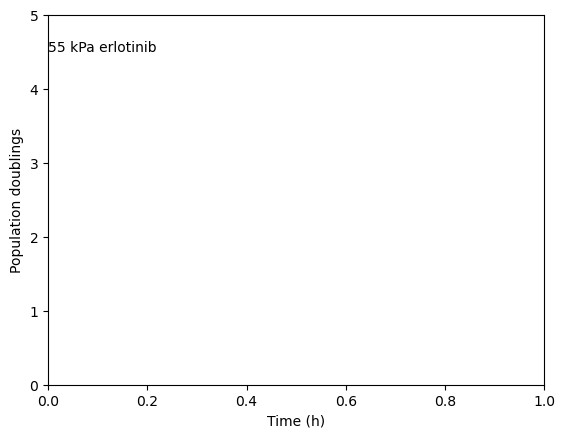

In [51]:
# Importing the parameters:
new_param = pd.read_csv(os.getcwd()+ '/test_treatments/parameters.csv')
for key in new_param.keys():
    try:
        if model.parameters[key].value != new_param[key][0]:
            model.parameters[key].value = new_param[key]
    except:
        print(key)
model.parameters['omega'].value = 200

concs = [0, 0.001, 0.01, 0.025, 0.05, 0.075, 0.1, 0.25, 0.5, 1, 2, 5, 10]
DIPs_ei = dict([(conc, []) for conc in concs])
cell_counts_ei = dict([(conc, []) for conc in concs])
colors = plt.cm.jet(np.linspace(0,1,len(concs)))

fig, ax = make_fig(cell_count, run_time, title=condition)
n=0
for conc in concs:
    for i in range(3):
        cells, cell_count = run_treatment('CycEi_0', conc)
        cell_counts_ei[conc].append(cell_count)
        dip_rate = fit_DIP(cell_count, run_time)
        DIPs_ei[conc].append(dip_rate)
        add_plot(cell_count, run_time, fig, ax, title=condition, color=colors[n])
        
    n+=1
        

In [ ]:
# Importing the parameters:
new_param = pd.read_csv(os.getcwd()+ '/test_treatments/parameters.csv')
for key in new_param.keys():
    try:
        if model.parameters[key].value != new_param[key][0]:
            model.parameters[key].value = new_param[key]
    except:
        print(key)
model.parameters['omega'].value = 200

concs = [0, 0.001, 0.01, 0.025, 0.05, 0.075, 0.1, 0.25, 0.5, 1, 2, 5, 10]
DIPs_ai = dict([(conc, []) for conc in concs])
cell_counts_ai = dict([(conc, []) for conc in concs])
colors = plt.cm.jet(np.linspace(0,1,len(concs)))

fig, ax = make_fig(cell_count, run_time, title=condition)
n=0
for conc in concs:
    for i in range(3):
        cells, cell_count = run_treatment('CycAi_0', conc)
        cell_counts_ai[conc].append(cell_count)
        dip_rate = fit_DIP(cell_count, run_time)
        DIPs_ai[conc].append(dip_rate)
        add_plot(cell_count, run_time, fig, ax, title=condition, color=colors[n])
        
    n+=1
        

In [ ]:
# Importing the parameters:
new_param = pd.read_csv(os.getcwd()+ '/test_treatments/parameters.csv')
for key in new_param.keys():
    try:
        if model.parameters[key].value != new_param[key][0]:
            model.parameters[key].value = new_param[key]
    except:
        print(key)
model.parameters['omega'].value = 200

concs = [0, 0.001, 0.01, 0.025, 0.05, 0.075, 0.1, 0.25, 0.5, 1, 2, 5, 10]
DIPs_bi = dict([(conc, []) for conc in concs])
cell_counts_bi = dict([(conc, []) for conc in concs])
colors = plt.cm.jet(np.linspace(0,1,len(concs)))

fig, ax = make_fig(cell_count, run_time, title=condition)
n=0
for conc in concs:
    for i in range(3):
        cells, cell_count = run_treatment('CycBi_0', conc)
        cell_counts_bi[conc].append(cell_count)
        dip_rate = fit_DIP(cell_count, run_time)
        DIPs_bi[conc].append(dip_rate)
        add_plot(cell_count, run_time, fig, ax, title=condition, color=colors[n])
        
    n+=1
        

In [ ]:
params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

In [ ]:
def plot_dip(concs, DIPs, title="Unknown Condition"):
    fig, ax = plt.subplots()
    
    ax.set_xlabel('Conc (um)')
    ax.set_ylabel('DIP')
    plt.xscale("log")
    ax.set_ylim(-0.01,0.03)
    #plt.text(0,4.5,title)
    for conc in concs:
        tmp_c = [conc*10e-7]*len(DIPs[conc])
        ax.scatter(tmp_c,DIPs[conc], color='black')
    
    return fig, ax

In [ ]:
def plot_arate(concs, population_dfs, title="Unknown Condition"):
    fig1 = plt.figure()
    ax = fig1.add_subplot(1,1,1)
    
    ax.set_xlabel('Conc (um)')
    ax.set_ylabel('Apoptosis rate')
    ax.set_xscale("log")
    ax.set_xlim(1.0e-10, 1.0e-4)
    # ax.set_ylim(-0.01,0.03)
    #plt.text(0,4.5,title)
    for conc in concs:
        a_rates = []
        for num in range(3):
            tmp_rates, _, _ = calc_rates(population_dfs[conc][num])
            a_rates.append(tmp_rates['a'])

        tmp_c = [conc*10e-7]*3
        ax.scatter(tmp_c,a_rates, color='black')
    
    return fig, ax

In [ ]:
def plot_drate(concs, population_dfs, title="Unknown Condition"):
    fig1 = plt.figure()
    ax = fig1.add_subplot(1,1,1)
    
    ax.set_xlabel('CycDi (M)')
    ax.set_ylabel('Division rate')
    ax.set_xscale("log")
    ax.set_xlim(1.0e-10, 1.0e-4)
    # ax.set_ylim(-0.01,0.03)
    #plt.text(0,4.5,title)
    for conc in concs:
        d_rates = []
        for num in range(3):
            tmp_rates, _, _ = calc_rates(population_dfs[conc][num])
            d_rates.append(tmp_rates['d'])

        tmp_c = [conc*10e-7]*3
        ax.scatter(tmp_c,d_rates, color='black')
    
    return fig, ax

In [ ]:
def plot_qrate(concs, population_dfs, title="Unknown Condition"):
    fig, ax = plt.subplots()
    
    ax.set_xlabel('Conc (um)')
    ax.set_ylabel('Quiescence rate')
    plt.xscale("log")
    # ax.set_ylim(-0.01,0.03)
    #plt.text(0,4.5,title)
    for conc in concs:
        q_rates = []
        for num in range(3):
            tmp_rates = calc_rates(population_dfs[conc][num])
            q_rates.append(tmp_rates['q'])

        tmp_c = [conc*10e-7]*3
        ax.scatter(tmp_c,q_rates, color='black')
    
    return fig, ax

In [ ]:
def plot_daratio(concs, population_dfs, title="Unknown Condition"):
    fig, ax = plt.subplots()
    
    ax.set_xlabel('Conc (um)')
    ax.set_ylabel('Division/Apoptosis rate')
    plt.xscale("log")
    # ax.set_ylim(-0.01,0.03)
    #plt.text(0,4.5,title)
    for conc in concs:
        d_rates = []
        a_rates = []
        for num in range(3):
            tmp_rates = calc_rates(population_dfs[conc][num])
            d_rates.append(tmp_rates['d'])
            a_rates.append(tmp_rates['a'])
            
            d_a = np.mean(d_rates)/np.mean(a_rates)

        tmp_c = [conc*10e-7]*1
        ax.scatter(tmp_c,d_a, color='black')
    
    return fig, ax

In [ ]:
def plot_divdeath_totals(concs, population_dfs, title="Unknown Condition"):
    fig, ax = plt.subplots()
    
    ax.set_xlabel('Conc (um)')
    plt.xscale("log")

    for conc in concs:
        d_rates = []
        a_rates = []
        for num in range(3):
            tmp_rates, death_num, div_num = calc_rates(population_dfs[conc][num])
            tot_events = death_num + div_num
            a_rates.append(death_num/tot_events)
            d_rates.append(div_num/tot_events)
            

        tmp_c = [conc*10e-7]*3
        # ax.scatter(tmp_c,d_rates, color='tab:blue')
        ax.scatter(tmp_c,a_rates, color='tab:red')

    return fig, ax


In [ ]:
def plot_numberdeaths(concs, population_dfs, title="Unknown Condition"):
    fig1 = plt.figure()
    ax = fig1.add_subplot(1,1,1)
    
    ax.set_xlabel('Conc (um)')
    ax.set_ylabel('Death Count')
    ax.set_xscale("log")
    ax.set_xlim(1.0e-10, 1.0e-4)
    # ax.set_ylim(-0.01,0.03)
    #plt.text(0,4.5,title)
    for conc in concs:
        a_rates = []
        deaths = []
        for num in range(3):
            tmp_rates, tot_deaths, _ = calc_rates(population_dfs[conc][num])
            a_rates.append(tmp_rates['a'])
            deaths.append(tot_deaths)

        tmp_c = [conc*10e-7]*3
        ax.scatter(tmp_c,deaths, color='black')
    
    return fig, ax

In [ ]:
def plot_death_avgdiv(concs, population_dfs, title="Unknown Condition"):
    fig1 = plt.figure()
    ax = fig1.add_subplot(1,1,1)
    
    ax.set_xlabel('Conc (um)')
    ax.set_ylabel('Death Count/Avg. Division Time')
    ax.set_xscale("log")
    ax.set_xlim(1.0e-10, 1.0e-4)
    # ax.set_ylim(-0.01,0.03)
    #plt.text(0,4.5,title)
    n=0
    for conc in concs:
        a_rates = []
        deaths = []
        deathperdiv = []
        for num in range(3):
            tmp_rates, tot_deaths, _ = calc_rates(population_dfs[conc][num])
            a_rates.append(tmp_rates['a'])
            deaths.append(tot_deaths)
            deathperdiv.append(tot_deaths/avg_div_len[n])

        tmp_c = [conc*10e-7]
        ax.scatter(tmp_c,tot_deaths/avg_div_len[n], color='black')
        n+=1
    return fig, ax

In [ ]:
rates, death_num, div_num = calc_rates(population_df)

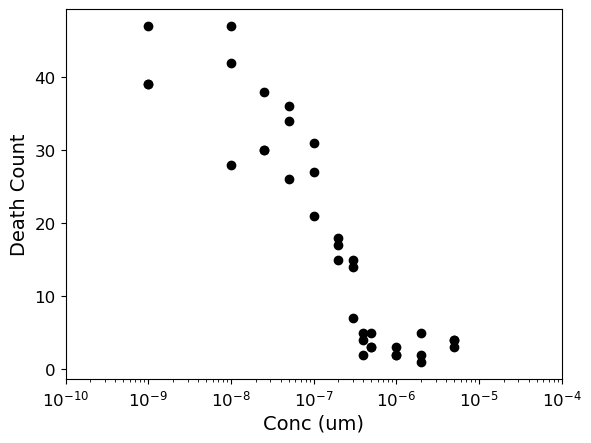

In [ ]:
fig, ax = plot_numberdeaths(concs, population_dfs, title="Unknown Condition")

NameError: name 'avg_div_len' is not defined

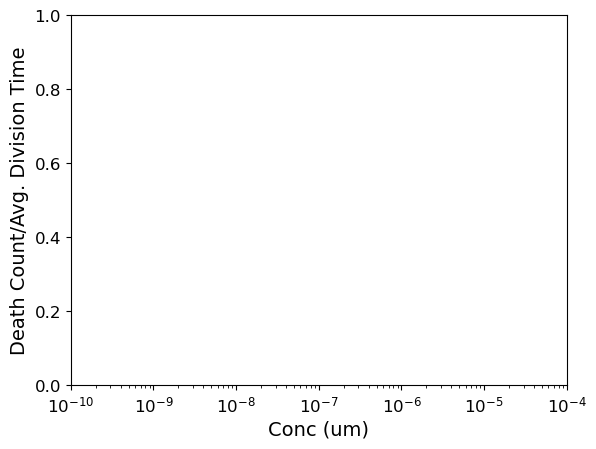

In [ ]:
fig, ax = plot_death_avgdiv(concs, population_dfs, title="Unknown Condition")

In [ ]:
all_div_len = {0: [27.47252747252747, 27.839643652561247, 27.716186252771617],
 0.001: [27.77777777777778, 27.716186252771617, 28.28054298642534],
 0.01: [28.538812785388128, 28.86836027713626, 28.409090909090907],
 0.025: [30.339805825242717, 29.274004683840747, 30.048076923076927],
 0.05: [32.808398950131235, 31.9693094629156, 32.552083333333336],
 0.075: [34.62603878116344, 34.24657534246575, 33.24468085106383],
 0.1: [37.20238095238095, 36.231884057971016, 35.51136363636363],
 0.25: [44.642857142857146, 43.40277777777778, 46.125461254612546],
 0.5: [56.81818181818181, 55.80357142857143, 58.13953488372093],
 1: [62.5, 62.5, 68.30601092896175],
 2: [70.2247191011236, 77.63975155279502, 76.21951219512195],
 5: [78.125, 74.4047619047619, 75.75757575757576],
 10: [89.28571428571429, 83.33333333333333, 82.78145695364238]}

In [ ]:
avg_div_len = []
for conc in concs:
    avg_div_len.append(np.mean(all_div_len[conc]))

In [ ]:
avg_div_len

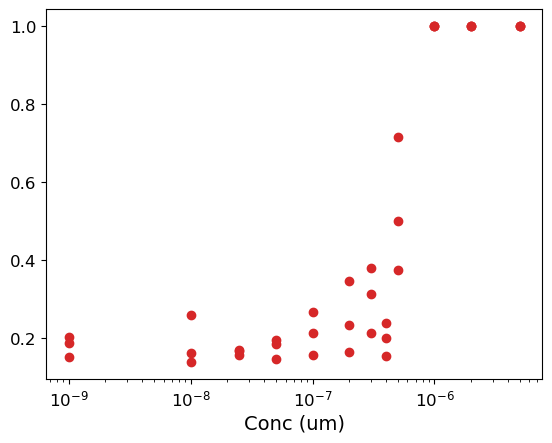

In [ ]:
fig, ax = plot_divdeath_totals(concs, population_dfs, title="Unknown Condition")
# ax.set_ylim(0, 1)
# ax.set_xlim(0.0003, 50)

In [ ]:
no_divs = {0: [0.0061512720830667784, 0.005354565348977975, 0.004729343606518611],
 0.001: [0.005728232715680414, 0.004926530437390224, 0.004906570715950444],
 0.01: [0.006281249214843848, 0.0052431511338314335, 0.004284091120755491],
 0.025: [0.005657708628005658, 0.005955642375586631, 0.005131055714713302],
 0.05: [0.006316454363617221, 0.006013807702484905, 0.005451373746184037],
 0.075: [0.0052501476604029495, 0.005067088248408934, 0.0055289347585698485],
 0.1: [0.007584951456310679, 0.006427595811350063, 0.004793264421473824],
 0.25: [0.005138416083242341, 0.004911276718413016, 0.006476851731910153],
 0.5: [0.004729493532931669, 0.004649000464900046, 0.007585641897017326],
 1: [0.005850661856122473, 0.004396570674873598, 0.0050784856879039705],
 2: [0.005396290050590219, 0.004602903665062042, 0.007363553356307619],
 5: [0.005354440693749273, 0.006975446428571428, 0.007466252538525863],
 10: [0.005457770500750442, 0.0032538313864575535, 0.004225999081304547]}

In [ ]:
population_dfs.keys()

dict_keys([0, 0.001, 0.01, 0.025, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 1, 2, 5])

In [ ]:
fig, ax = plot_arate(concs, population_dfs, title="Unknown Condition")
ax.set_xlim(1.0e-10, 1.0e-4)
ax.set_ylim(0.001,0.009)

#plt.text(0,4.5,title)
concs = [0, 0.001, 0.01, 0.025, 0.05, 0.075, 0.1, 0.25, 0.5, 1, 2, 5, 10]
for conc in concs:
#     a_rates = []
#     for num in range(3):
# #         tmp_rates = calc_rates(population_dfs[conc][num])
#         a_rates.append(tmp_rates['a'])

    tmp_c = [conc*10e-7]*3
    ax.scatter(tmp_c,no_divs[conc], color='red')

In [ ]:
fig, ax = plot_drate(concs, population_dfs, title="Unknown Condition")

ax.set_xlim(1.0e-10, 1.0e-4)
ax.set_ylim(0.001,0.028)
#plt.text(0,4.5,title)
for conc in concs:
#     a_rates = []
#     for num in range(3):
# #         tmp_rates = calc_rates(population_dfs[conc][num])
#         a_rates.append(tmp_rates['a'])

    tmp_c = [conc*10e-7]*3
    ax.scatter(tmp_c,no_divs[conc], color='red')
    
ax.set_ylabel('Division or Apoptosis rate', fontsize=22)
ax.set_yticklabels(ax.get_yticklabels(), fontsize= 22)

ax.set_xlabel('CycDi (M)', fontsize=22)
ax.set_xticklabels(ax.get_xticklabels(), fontsize= 22)


In [ ]:
plot_drate(concs, population_dfs, title="Unknown Condition")

In [ ]:
plot_qrate(concs, population_dfs, title="Unknown Condition")

In [ ]:
plot_daratio(concs, population_dfs, title="Unknown Condition")

In [ ]:
a_rate_di[concs[0]]

In [ ]:
plot_dip(concs, DIPs_di, title="Unknown Condition")

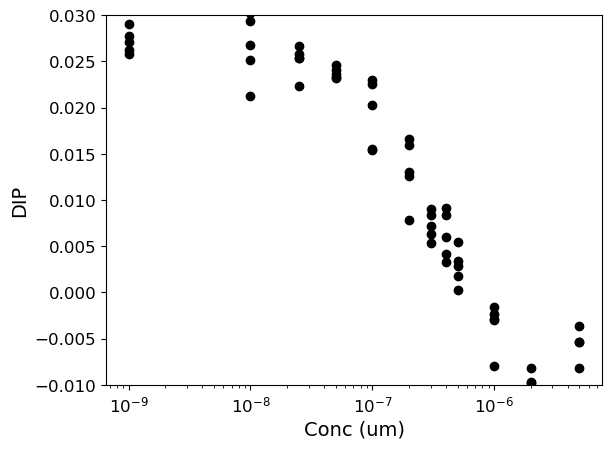

In [ ]:
fig, ax = plot_dip(concs, DIPs_di, title="Unknown Condition")
# ax.set_xlim(0.0003, 50)

In [ ]:
plot_dip(concs, DIPs_ai, title="Unknown Condition")

In [ ]:
plot_dip(concs, DIPs_bi, title="Unknown Condition")

In [ ]:
cell_counts_dil = {}
for cond in cell_counts_di:
    tmp = [run.tolist() for run in cell_counts_di[cond]]
    cell_counts_dil.update({cond: tmp})

In [ ]:
del cell_counts_dil[10]

In [ ]:
a_rates_dil = {}
for cond in a_rate_di:
    tmp = [run for run in a_rate_di[cond]]
    a_rates_dil.update({cond: tmp})

In [ ]:
    
cell_counts_eil = {}
for cond in cell_counts_ei:
    tmp = [run.tolist() for run in cell_counts_ei[cond]]
    cell_counts_eil.update({cond: tmp})
    
cell_counts_ail = {}
for cond in cell_counts_ai:
    tmp = [run.tolist() for run in cell_counts_ai[cond]]
    cell_counts_ail.update({cond: tmp})
    
cell_counts_bil = {}
for cond in cell_counts_bi:
    tmp = [run.tolist() for run in cell_counts_bi[cond]]
    cell_counts_bil.update({cond: tmp})

In [ ]:
import json

# e.g. file = './data.json' 
with open('C:\\Users\\olesk\\ECM_mod_output\\cell_counts_di_55kpa_erl2.json', 'w') as f: 
    json.dump(cell_counts_dil, f)

In [ ]:
# e.g. file = './data.json' 
with open('C:\\Users\\olesk\\ECM_mod_output\\arates_di_4kpa_erl.json', 'w') as f: 
    json.dump(a_rates_dil, f)

In [ ]:
plt.plot(cell_counts_di[0][0][:,0], cell_counts_di[0][0][:,1])
cell_counts_di[0][0]

In [ ]:
    
with open('C:\\Users\\olesk\\ECM_mod_output\\cell_counts_ei_4kpa_erl.json', 'w') as f: 
    json.dump(cell_counts_eil, f)
    
with open('C:\\Users\\olesk\\ECM_mod_output\\cell_counts_ai_4kpa_erl.json', 'w') as f: 
    json.dump(cell_counts_ail, f)
    
with open('C:\\Users\\olesk\\ECM_mod_output\\cell_counts_bi_4kpa_erl.json', 'w') as f: 
    json.dump(cell_counts_bil, f)

In [ ]:
fig, ax = make_fig(cell_count, run_time, title=condition)
add_plot(cell_count, run_time, fig, ax, title=condition)
add_plot(cell_count_1, run_time, fig, ax, title=condition, color='red')

In [ ]:
def runIMTs(init, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, IMTs_count):
    all_IMTs = []
    n = 0
    while len(all_IMTs)<IMTs_count:
        check, population_df, cells, cell_count = Cell_Population_Simulation(init, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, thr=[0.26, 0.14], return_plot=False, bypass=True)
        all_events_simulated = call_events(run_time, IMT_eoe_counts)
        
        mits = all_events_simulated.loc[all_events_simulated['event']=='mitosis'].reset_index()
        mits_list = mits['Lifespan'].tolist()
        mits_list_r = [round(x,1) for x in mits_list]

        IMT_tmp, s_m_tmp, g1_tmp = SMs_G1s_IMTs_extraction(cells)
        
        if n==0:
            all_IMTs = mits_list_r
            all_g1s = g1_tmp
        else:
            all_IMTs.extend(mits_list_r)
            all_g1s.extend(g1_tmp)
        
        # filename_cell_count = Path(SAVE_DIR, f'cell_counts_{condition}_{n}_cycdi_0_4.csv')
        # np.savetxt(filename_cell_count, cell_count, delimiter=',')
        
        n+=1
        
    filename_IMT = Path(SAVE_DIR, f'IMTs_{condition}_cycdi_0_4.csv')
    filename_g1 = Path(SAVE_DIR, f'G1s_{condition}_cycdi_0_4.csv')
    np.savetxt(filename_IMT, all_IMTs, delimiter=',')
    np.savetxt(filename_g1, all_g1s, delimiter=',')



In [ ]:
SAVE_DIR

WindowsPath('C:/Users/olesk/ECM_mod_output')

In [ ]:
condition = "55 kPa erlotinib"

In [ ]:
runIMTs(20, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, 200)


55 kPa erlotinib
BAXm_0
BCL2_0


2024-04-22 23:20:41.425 - pysb.simulator.scipyode - WARNING - [cell_cycle_death_model] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


55 kPa erlotinib
BAXm_0
BCL2_0


2024-04-22 23:22:26.371 - pysb.simulator.scipyode - WARNING - [cell_cycle_death_model] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


55 kPa erlotinib
BAXm_0
BCL2_0


...

2024-04-22 23:42:40.044 - pysb.simulator.scipyode - WARNING - [cell_cycle_death_model] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


55 kPa erlotinib
BAXm_0
BCL2_0


2024-04-22 23:44:14.962 - pysb.simulator.scipyode - WARNING - [cell_cycle_death_model] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


55 kPa erlotinib
BAXm_0
BCL2_0


2024-04-22 23:45:52.113 - pysb.simulator.scipyode - WARNING - [cell_cycle_death_model] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


In [ ]:
condition = "4 kPa DMSO"

In [ ]:
all_IMTs = []
n = 2

(population_df, cells, cell_count) = Cell_Population_Simulation(5, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, thr=0.26, return_plot=False)

IMT_eoe_counts, all_prot = retrieve_cellState(run_time, cells, return_all_prot=True)
all_events_simulated = call_events(run_time, IMT_eoe_counts)

mits = all_events_simulated.loc[all_events_simulated['event']=='mitosis'].reset_index()
mits_list = mits['Lifespan'].tolist()
mits_list_r = [round(x,1) for x in mits_list]

if n==0:
    all_IMTs = mits_list_r
else:
    all_IMTs.extend(mits_list_r)

filename_cell_count = Path(SAVE_DIR, f'cell_counts_{condition}_{n}_param_orig.csv')
np.savetxt(filename_cell_count, cell_count, delimiter=',')

n+=1

In [ ]:
all_conditions = ['0.6 kPa DMSO', '4 kPa erlotinib', '4 kPa DMSO', '55 kPa erlotinib', '55 kPa DMSO']

In [ ]:
for condition in all_conditions:
    runIMTs(5, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, 200)

In [ ]:
death_before_division = len(max_tmp_cdc)==0 or np.min(death) < max_tmp_cdc[min([cells['division'][0], len(max_tmp_cdc)-1])]
death_before_division

In [ ]:
div_ind=[]
len(div_ind)

In [ ]:
start = all_events_simulated.loc[all_events_simulated['event']=='Starting cell']
start

In [ ]:
mits = all_events_simulated.loc[all_events_simulated['event']=='mitosis'].reset_index()

In [ ]:
mits_list = mits['Lifespan'].tolist()
mits_list_r = [round(x,1) for x in mits_list]
mits_list_r

In [ ]:
cells['living_cell'][0]

In [ ]:
cells['division'][0]

In [ ]:
plt.plot(cells['time'][0],cells['molecules'][0]['obsBAXm'])
plt.plot(cells['time'][0],cells['molecules'][0]['obsCdc20'])

In [ ]:
start_time = datetime.datetime.now()

conditions = ['4 kPa erlotinib', '4 kPa DMSO', '55 kPa erlotinib', '55 kPa DMSO']


for condition in conditions:
    for num in range(3):
        init = 5
        
        (cells, cell_count) = Cell_Population_Simulation(init, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, seed=seed)
        
        filename = Path(SAVE_DIR, f'cells_{condition}_{num}_param_orig.csv')
        if OVERWRITE or not os.path.exists(filename):
            print(f"Saving to {filename}...")
            with open(filename, 'wb') as f:
                pickle.dump(cells, f, protocol=pickle.HIGHEST_PROTOCOL)
        else:
            print(f"File {filename} already exists. Skipping...")
            
        filename = Path(SAVE_DIR, f'cellcount_{condition}_{num}_param_orig.csv')
        if OVERWRITE or not os.path.exists(filename):
            print(f"Saving to {filename}...")
            np.savetxt(filename, cell_count, delimiter=',')
        else:
            print(f"File {filename} already exists. Skipping...")
        current_time = datetime.datetime.now()
        print(f'elapsed time is {(current_time-start_time)/60} minutes')

In [ ]:
conditions = ['0.6 kPa erlotinib', '0.6 kPa DMSO']

for condition in conditions:
    for num in range(3):
        init = 10
        
        (cells, cell_count) = Cell_Population_Simulation(init, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, seed=seed)
        
        filename = Path(SAVE_DIR, f'cells_{condition}_{num}_param_orig.csv')
        if OVERWRITE or not os.path.exists(filename):
            print(f"Saving to {filename}...")
            with open(filename, 'wb') as f:
                pickle.dump(cells, f, protocol=pickle.HIGHEST_PROTOCOL)
        else:
            print(f"File {filename} already exists. Skipping...")
            
        filename = Path(SAVE_DIR, f'cellcount_{condition}_{num}_param_orig.csv')
        if OVERWRITE or not os.path.exists(filename):
            print(f"Saving to {filename}...")
            np.savetxt(filename, cell_count, delimiter=',')
        else:
            print(f"File {filename} already exists. Skipping...")

In [ ]:
conditions = ['0.6 kPa erlotinib', '0.6 kPa DMSO']

fig, ax = plt.subplots()
for condition in conditions:
    for num in range(3):
            
        filename = Path(SAVE_DIR, f'cellcount_{condition}_{num}_param_orig.csv')

        print(f"Loading {filename}...")
        cell_count = np.loadtxt(filename, delimiter=',')
        
        t_sim = np.arange(0, 120, 1 / 3)
        cell_count_t = np.zeros(len(t_sim))
        time_tmp_m = 0
        for time_tmp_p, cell_count_time_tmp in cell_count:
            cell_count_t[(time_tmp_m <= t_sim) & (t_sim < time_tmp_p)] = cell_count_time_tmp
            time_tmp_m = time_tmp_p
        DIP_sim = np.log2(cell_count_t / cell_count_t[0])
        if "erlotinib" in str(filename):
            ax.scatter(t_sim, DIP_sim, color="red", s=1)
        else:
            ax.scatter(t_sim, DIP_sim, color="blue", s=1)
ax.set_xlabel('Time (h)')
ax.set_ylabel('Population doublings')
ax.set_ylim(0,5)
plt.text(0,4.75,conditions[1])
plt.text(0,4.45,conditions[0])
plt.show()

In [ ]:
conditions = ['4 kPa erlotinib', '4 kPa DMSO']

fig, ax = plt.subplots()
for condition in conditions:
    for num in range(3):
            
        filename = Path(SAVE_DIR, f'cellcount_{condition}_{num}_param_orig.csv')

        print(f"Loading {filename}...")
        cell_count = np.loadtxt(filename, delimiter=',')
        
        t_sim = np.arange(0, 120, 1 / 3)
        cell_count_t = np.zeros(len(t_sim))
        time_tmp_m = 0
        for time_tmp_p, cell_count_time_tmp in cell_count:
            cell_count_t[(time_tmp_m <= t_sim) & (t_sim < time_tmp_p)] = cell_count_time_tmp
            time_tmp_m = time_tmp_p
        DIP_sim = np.log2(cell_count_t / cell_count_t[0])
        if "erlotinib" in str(filename):
            ax.scatter(t_sim, DIP_sim, color="red", s=1)
        else:
            ax.scatter(t_sim, DIP_sim, color="blue", s=1)
ax.set_xlabel('Time (h)')
ax.set_ylabel('Population doublings')
ax.set_ylim(0,5)
plt.text(0,4.75,conditions[1])
plt.text(0,4.45,conditions[0])
plt.show()

In [ ]:
conditions = ['55 kPa erlotinib', '55 kPa DMSO']

fig, ax = plt.subplots()
for condition in conditions:
    for num in range(3):
            
        filename = Path(SAVE_DIR, f'cellcount_{condition}_{num}_param_orig.csv')

        print(f"Loading {filename}...")
        cell_count = np.loadtxt(filename, delimiter=',')
        
        t_sim = np.arange(0, 120, 1 / 3)
        cell_count_t = np.zeros(len(t_sim))
        time_tmp_m = 0
        for time_tmp_p, cell_count_time_tmp in cell_count:
            cell_count_t[(time_tmp_m <= t_sim) & (t_sim < time_tmp_p)] = cell_count_time_tmp
            time_tmp_m = time_tmp_p
        DIP_sim = np.log2(cell_count_t / cell_count_t[0])
        if "erlotinib" in str(filename):
            ax.scatter(t_sim, DIP_sim, color="red", s=1)
        else:
            ax.scatter(t_sim, DIP_sim, color="blue", s=1)
ax.set_xlabel('Time (h)')
ax.set_ylabel('Population doublings')
ax.set_ylim(0,5)
plt.text(0,4.75,conditions[1])
plt.text(0,4.45,conditions[0])
plt.show()